# 03 · LSH — Title & review-text uniqueness (Arts, Crafts & Sewing)

Uses MinHash LSH (Jaccard similarity ≥ 0.7) to measure how many review titles and texts are near-duplicates, for the whole category, its top 5 products, and pre-2022 vs. 2022+ reviews.

## Environment

In [ ]:
!pip install pyspark -q
!apt-get install openjdk-8-jdk-headless -qq > /dev/null

import os
import time
from google.colab import drive
import gc
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, trunc, desc, month, date_format, avg, count, regexp_replace, when, countDistinct, explode, split, lower, monotonically_increasing_id, lit, trim, length

if not os.path.exists('/content/drive'):
    drive.mount('/content/drive')

spark = SparkSession.builder \
    .appName("Amazon_LSH_StepByStep") \
    .master("local[*]") \
    .config("spark.driver.memory", "24g") \
    .config("spark.executor.memory", "24g") \
    .config("spark.sql.shuffle.partitions", "200") \
    .config("spark.memory.offHeap.enabled", "true") \
    .config("spark.memory.offHeap.size", "8g") \
    .getOrCreate()

In [ ]:
DRIVE_BASE = "/content/drive/My Drive/BDCC_Final_Project"
DRIVE_REVIEWS = f"{DRIVE_BASE}/cleaned_review_spark"
DRIVE_META = f"{DRIVE_BASE}/cleaned_meta_spark"

LOCAL_BASE = "/content/data"
LOCAL_REVIEWS = f"{LOCAL_BASE}/reviews"
LOCAL_META = f"{LOCAL_BASE}/meta"

os.makedirs(LOCAL_REVIEWS, exist_ok=True)
os.makedirs(LOCAL_META, exist_ok=True)

In [ ]:
import time
start_time = time.time()


!cp -r "{DRIVE_REVIEWS}/"* "{LOCAL_REVIEWS}/"


print(f"Copying Meta from {DRIVE_META}...")
!cp -r "{DRIVE_META}/"* "{LOCAL_META}/"

end_time = time.time()
print(f"Data Transfer Complete! Time taken: {end_time - start_time:.2f} seconds")


Copying Meta from /content/drive/My Drive/BDCC_Final_Project/cleaned_meta_spark...
Data Transfer Complete! Time taken: 196.57 seconds


In [ ]:
print("Verifying local files:")
!ls -lh "{LOCAL_REVIEWS}" | head -n 5

Verifying local files:
total 40K
drwx------ 2 root root 4.0K Dec  7 23:36 batch_001
drwx------ 2 root root 4.0K Dec  7 23:36 batch_002
drwx------ 2 root root 4.0K Dec  7 23:37 batch_003
drwx------ 2 root root 4.0K Dec  7 23:37 batch_004


In [ ]:
df_reviews = spark.read.option("mergeSchema", "true").parquet(f"{LOCAL_REVIEWS}/*")
df_meta = spark.read.option("mergeSchema", "true").parquet(f"{LOCAL_META}/*")

review_count = df_reviews.count()
meta_count = df_meta.count()

print(f"Reviews Count: {review_count}")
print(f"Meta Count: {meta_count}")

Reviews Count: 64679785
Meta Count: 4071089


## Create Dataset for “Arts, Crafts & Sewing”

In [ ]:
df_cat = df_meta.filter(col("main_category") == "Arts, Crafts & Sewing").join(df_reviews, "parent_asin", "inner").withColumn("id", monotonically_increasing_id()).select("id", "product_title", "title", "text", "year")
df_cat.cache()
df_cat.count()

46403

In [ ]:
df_meta.unpersist()
df_reviews.unpersist()

DataFrame[parent_asin: string, user_id: string, rating: double, title: string, text: string, review_date: date, year: int]

#  Uniqueness & Effectiveness Tests for “Arts, Crafts & Sewing”

In [ ]:
if 'analysis_results' not in locals():
    analysis_results = {}

In [ ]:
from pyspark.ml.feature import Tokenizer, HashingTF, MinHashLSH
from pyspark.sql.functions import col, countDistinct

def run_lsh_product_final(df_input, target_col="text", threshold=0.7):
    df_clean = df_input.filter(length(col(target_col)) > 2)
    total_rows = df_clean.count()

    if total_rows < 2: return 0.0

    tokenizer = Tokenizer(inputCol=target_col, outputCol="tokens")
    df_tokens = tokenizer.transform(df_clean)

    hashingTF = HashingTF(inputCol="tokens", outputCol="features", numFeatures=1024)
    df_hashed = hashingTF.transform(df_tokens)

    df_light = df_hashed.select("id", "features")

    mh = MinHashLSH(inputCol="features", outputCol="hashes", numHashTables=2)
    model = mh.fit(df_light)

    dist = 1.0 - threshold

    df_pairs = model.approxSimilarityJoin(df_light, df_light, dist, distCol="dist") \
        .filter("datasetA.id < datasetB.id")

    unique_dupe_rows = df_pairs.select(col("datasetA.id")).distinct().count()

    real_ratio = (unique_dupe_rows / total_rows) * 100

    return real_ratio

Processing 1/5: Kit Cat Klock Gentlemen (Galax...
Processing 2/5: Leather and Vinyl Repair Kit -...
Processing 3/5: Silhouette America, Inc Tempor...
Processing 4/5: Science Purchase 78VK14226-3 2...
Processing 5/5: 2000 Pieces Flat Back Gems Rhi...


,Product Name,Full Name,Title Duplication,Text Duplication
0,Prod 1,Kit Cat Klock Gentlemen (Galaxy Blue)...,26.53%,1.83%
1,Prod 2,"Leather and Vinyl Repair Kit - Furniture, Couch, C...",31.18%,3.76%
2,Prod 3,"Silhouette America, Inc Temporary Tattoo Paper, 8....",22.60%,2.01%
3,Prod 4,Science Purchase 78VK14226-3 22Piece Pink Professi...,28.06%,1.40%
4,Prod 5,2000 Pieces Flat Back Gems Rhinestones 6 Sizes (1....,18.17%,3.91%


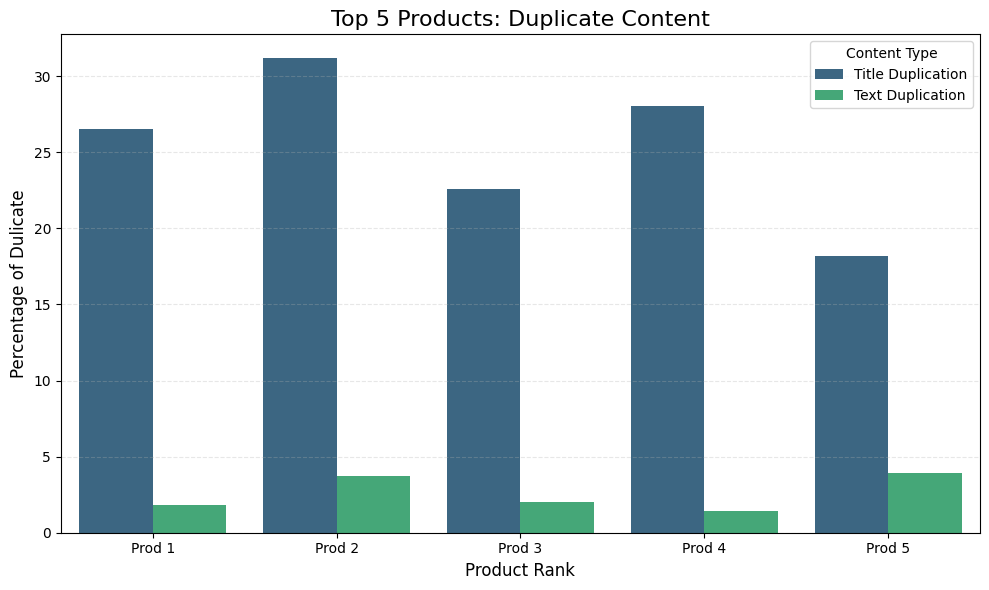

In [ ]:
top_5_df = df_cat.groupBy("product_title").count().orderBy(desc("count")).limit(5).toPandas()
top_5_names = top_5_df['product_title'].tolist()

product_results = []

for i, prod_name in enumerate(top_5_names):
    print(f"Processing {i+1}/5: {prod_name[:30]}...")

    df_prod = df_cat.filter(col("product_title") == prod_name)

    t_score = run_lsh_product_final(df_prod, "title", threshold=0.7)
    r_score = run_lsh_product_final(df_prod, "text", threshold=0.7)

    product_results.append({
        "Product Name": f"Prod {i+1}",
        "Full Name": prod_name[:50] + "...",
        "Title Duplication": t_score,
        "Text Duplication": r_score
    })


df_results = pd.DataFrame(product_results)

display(df_results.style.format({
    'Title Duplication': '{:.2f}%',
    'Text Duplication': '{:.2f}%'
}))

plt.figure(figsize=(10, 6))

df_melt = df_results.melt(
    id_vars=["Product Name"],
    value_vars=["Title Duplication", "Text Duplication"],
    var_name="Type",
    value_name="Score"
)

sns.barplot(data=df_melt, x="Product Name", y="Score", hue="Type", palette="viridis")
plt.title("Top 5 Products: Duplicate Content", fontsize=16)
plt.ylabel("Percentage of Dulicate", fontsize=12)
plt.xlabel("Product Rank", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()

In [ ]:
overall_results = {}

overall_results['title'] = run_lsh_product_final(df_cat, "title", threshold=0.7)
overall_results['text'] = run_lsh_product_final(df_cat, "text", threshold=0.7)

df_recent = df_cat.filter(col("year") >= 2022)
df_older = df_cat.filter(col("year") < 2022)

print(f"Recent Rows: {df_recent.count()}")
print(f"Older Rows: {df_older.count()}")

Recent Rows: 5307
Older Rows: 41096


In [ ]:
overall_results['recent_text'] = run_lsh_product_final(df_recent, "text", threshold=0.7)
overall_results['recent_title'] = run_lsh_product_final(df_recent, "title", threshold=0.7)

overall_results['older_text'] = run_lsh_product_final(df_older, "text", threshold=0.7)
overall_results['older_title'] = run_lsh_product_final(df_older, "title", threshold=0.7)

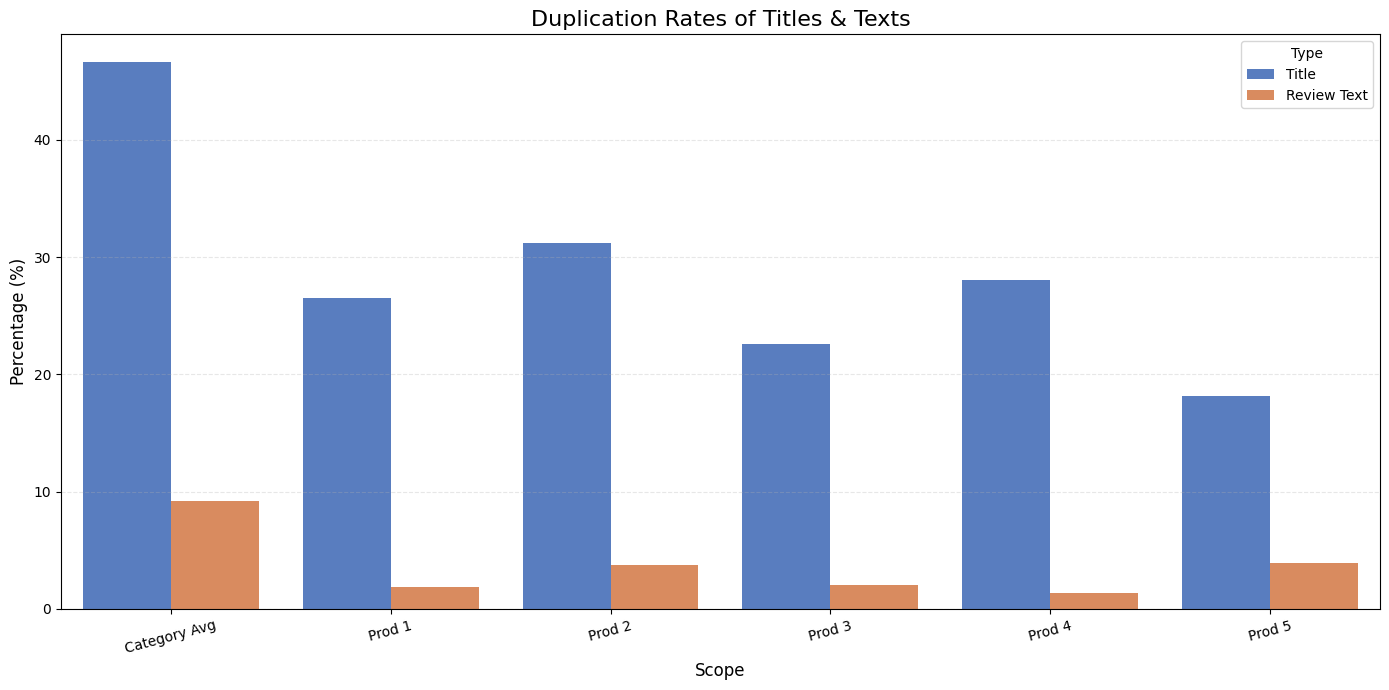

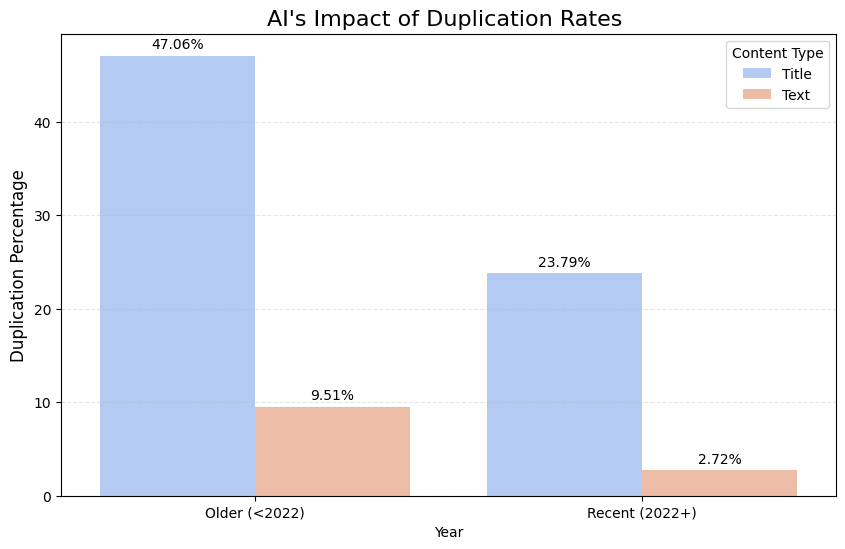

In [ ]:
viz_data = []

if 'overall_results' in locals():
    viz_data.append({
        "Scope": "Category Avg",
        "Type": "Title",
        "Score": overall_results.get('title', 0)
    })
    viz_data.append({
        "Scope": "Category Avg",
        "Type": "Review Text",
        "Score": overall_results.get('text', 0)
    })

for p in product_results:
    viz_data.append({
        "Scope": p['Product Name'],
        "Type": "Title",
        "Score": p['Title Duplication']
    })
    viz_data.append({
        "Scope": p['Product Name'],
        "Type": "Review Text",
        "Score": p['Text Duplication']
    })

df_viz = pd.DataFrame(viz_data)


plt.figure(figsize=(14, 7))
sns.barplot(data=df_viz, x="Scope", y="Score", hue="Type", palette="muted")

plt.title("Duplication Rates of Titles & Texts", fontsize=16)
plt.ylabel("Percentage (%)", fontsize=12)
plt.xlabel("Scope", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

if 'overall_results' in locals() and 'recent_text' in overall_results:
    plt.figure(figsize=(10, 6))

    time_viz_data = [
        {"Year": "Older (<2022)", "Type": "Title", "Score": overall_results['older_title']},
        {"Year": "Older (<2022)", "Type": "Text", "Score": overall_results['older_text']},
        {"Year": "Recent (2022+)", "Type": "Title", "Score": overall_results['recent_title']},
        {"Year": "Recent (2022+)", "Type": "Text", "Score": overall_results['recent_text']}
    ]

    time_data = pd.DataFrame(time_viz_data)

    ax = sns.barplot(data=time_data, x="Year", y="Score", hue="Type", palette="coolwarm")

    plt.title("AI's Impact of Duplication Rates ", fontsize=16)
    plt.ylabel("Duplication Percentage", fontsize=12)
    plt.grid(axis='y', linestyle='--', alpha=0.3)
    plt.legend(title="Content Type")

    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f%%', padding=3)

    plt.show()

In [ ]:
df_viz.head(15)

,Scope,Type,Score
0,Category Avg,Title,46.672312
1,Category Avg,Review Text,9.163545
2,Prod 1,Title,26.525728
3,Prod 1,Review Text,1.833400
4,Prod 2,Title,31.182796
5,Prod 2,Review Text,3.758389
6,Prod 3,Title,22.603550
7,Prod 3,Review Text,2.007084
8,Prod 4,Title,28.056426
9,Prod 4,Review Text,1.395349
